# Fermi–Dirac machines as quantizations of neurons — a reproduction

**Paper.** A. He, N. Liu, M. M. Wilde, *Fermi–Dirac machines as
quantizations of neurons*, arXiv:2605.24386 (2026). Authors' code:
github.com/Alexheeeee/quantized-neurons (commit `9c2094c`).

This notebook lays out the reproduction as a scientific argument:
- the claim;
- how it was tested;
- the evidence;
- the alternative explanations that were checked;
- what does and does not survive.

It re-runs small experiments live (about a minute on a laptop CPU). Every
large result is loaded from the committed artifacts in `results/`. Full
provenance (commands, sweeps, rules declared before each run, audits) is in
`LOG.md`.

**Research question (falsifiable).** Do quantized neurons learn functions of
quantum states better than classical neurons that see the same measurement
information and have the same number of parameters? These are neurons whose
activation is applied to a non-commuting Hamiltonian,
f(ρ) = Tr[tanh(H(θ)/T) ρ].

**What would weaken the claim:**
- a classical neuron on the same measured Pauli expectations, trained as
  carefully, matches or beats the quantum neuron;
- or the quantum neuron wins only when the target is generated by its own
  model class.

**Contents:**
1. Problem statement and paper claim
2. Data, splits, metrics and evaluation protocol
3. The model in a few equations
4. Known-answer sanity checks
5. Model walkthrough
6. Small live experiment
7. Headline reproduction result
8. Fair baseline comparison
9. Controls and ablations
10. Robustness and uncertainty
11. Photonic assessment (MerLin adaptation)
12. Limitations
13. Claim-level conclusion

In [1]:
import copy
import json
import math
import sys
import tempfile
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

PROJECT_DIR = Path.cwd()
assert (PROJECT_DIR / "lib" / "runner.py").exists(), "run this notebook from papers/fermi_dirac_neurons"
for path in (PROJECT_DIR.parent.parent, PROJECT_DIR.parent):
    if str(path) not in sys.path:
        sys.path.insert(0, str(path))

from runtime_lib.config import deep_update, load_config
from runtime_lib.dtypes import resolve_config_dtypes
from fermi_dirac_neurons.lib import photonic as ph
from fermi_dirac_neurons.lib import theory_checks as tc
from fermi_dirac_neurons.lib.data import build_split, build_target
from fermi_dirac_neurons.lib.models import build_model
from fermi_dirac_neurons.lib.plotting import COLOURS, apply_style
from fermi_dirac_neurons.lib.runner import run_training

RESULTS = PROJECT_DIR / "results"
apply_style()
pd.set_option("display.precision", 3)
pd.set_option("display.width", 160)
# One colour per model role, used in every figure.
ROLE_COLOUR = {
    "quantum": COLOURS["quantum"],
    "commuting (B1)": COLOURS["commuting"],
    "B2": COLOURS["b2"],
    "B3 linear": COLOURS["linear"],
}


def load_cfg(name: str) -> dict:
    # Resolve a named config exactly as the shared runtime does: defaults.json overlaid by configs/<name>.json.
    overlay = json.loads((PROJECT_DIR / "configs" / f"{name}.json").read_text())
    cfg = deep_update(load_config(PROJECT_DIR / "configs" / "defaults.json"), copy.deepcopy(overlay))
    if "models" in overlay:
        cfg["models"] = overlay["models"]
    return resolve_config_dtypes(cfg)


def role(model: str) -> str:
    if model.startswith("b2"):
        return "B2"
    if model.startswith("b3") or model.endswith("_linear"):
        return "B3 linear"
    if model.startswith("classical"):
        return "commuting (B1)"
    return "quantum"


seed_table = pd.read_csv(RESULTS / "per_seed_values.csv")
print("per-seed records loaded:", len(seed_table))

per-seed records loaded: 6600


## 1. Problem statement and paper claim

A classical neuron computes φ(wᵀz + b) on spins z ∈ {−1, 1}ⁿ. The paper reads
the argument as a classical Hamiltonian and "quantizes" the neuron by
promoting spins to Pauli operators and allowing any parameterized k-local
Hamiltonian H(θ) = Σ_j θ_j H_j:

$$f_\theta(\rho) = \mathrm{Tr}\big[\varphi(H(\theta))\,\rho\big],\qquad \varphi(x) = \tanh(x/T).$$

When all terms commute (Z only) this reduces exactly to a classical neuron
averaged over the measurement distribution of ρ. The paper's numerical
claims, which this notebook tests, are:

| Claim | Statement | Paper evidence |
|---|---|---|
| C4 | Non-commuting TFIM neurons learn a TFIM-generated target with lower squared loss than commuting Ising (IM) neurons, at the same parameter count | Fig. 7 (tanh and softplus, 2 and 7 qubits) |
| C5 | Heisenberg neurons classify Haar-random states better than fully connected Ising (FCIM) neurons, n = 2…7 | Fig. 8, Table II |
| C6 | The nonlinear model Tr[tanh(H)ρ] learns better than the linear model Tr[Hρ], except for 2-qubit Heisenberg ("closure") | Fig. 9 |
| C8 | The advantage needs quantum (non-orthogonal) input data | text, pp. 4–5, 21–22 |

The theory claims C1–C3 (exact identities and estimators) are checked in
Section 4. C7 (BQP-completeness) is not numerically testable.

## 2. Data, splits, metrics and evaluation protocol

All data are synthetic, generated by the paper's procedure (Sec. VI A) and
the authors' notebooks. No dataset is downloaded.

- **Target:** a random Hamiltonian H* from the task's term set (TFIM or
  Heisenberg) with coefficients ζ ~ U[−2, 2]. The regression target is
  y(ρ) = Tr[tanh(H*/T) ρ]; the classification label is sign Tr[H* ρ]
  (authors' code).
- **Training states:** Figs. 7 and 9 use the authors' small set of basis,
  GHZ, maximally mixed and random mixed states (2ⁿ⁺¹ + 5 states). Fig. 8
  uses 1000 Haar-random pure states.
- **Held-out test set:** 500 Haar-random pure states, called the
  `validation` split in the code. The paper reports only training loss for
  Figs. 7 and 9, so this test set is our addition.
- **Selection split (fair comparison only):** 20 % of the training states,
  held out to choose learning rates. **The test set is never used for any
  choice.**
- **Metrics:**
  - squared loss (training) and test MSE, compared in decades (log10);
  - classification accuracy with the paper's code rule sign Tr[H(θ)ρ],
    compared in points.
- **Protocol:** full-batch gradient descent with exact gradients, η = 0.1,
  T = 2, initial θ ~ U[−0.5, 0.5]; 2000 / 500 / 10 000 epochs for
  Figs. 7 / 8 / 9.
- **Statistics:** every configuration runs over 10 seeds; the paper reports
  one unseeded run. Comparisons are paired by seed: two-sided Wilcoxon test,
  ties within 0.1 decade or 1 point.

The next cell builds one dataset (Fig. 7a, 2 qubits) and checks that every
state is a valid density matrix.

In [2]:
cfg = load_cfg("p5_sel_fig7_tanh_2q_eta0.1")      # Fig. 7a task with the fair-comparison splits
cfg["seed"] = 0
target = build_target(cfg)
train = build_split(cfg, "train", target)
test = build_split(cfg, "validation", target)
print("target terms:", target.labels)
print("target coefficients zeta:", np.round(target.zeta, 3))
for name, data in (("train (before selection hold-out)", train), ("test", test)):
    states = data.states
    hermitian = np.abs(states - states.conj().transpose(0, 2, 1)).max()
    trace = np.abs(np.trace(states, axis1=1, axis2=2) - 1).max()
    min_eig = min(np.linalg.eigvalsh(s).min() for s in states)
    print(f"{name:34s} {states.shape}  Hermitian err {hermitian:.1e}  trace err {trace:.1e}  min eigenvalue {min_eig:+.1e}  "
          f"target range [{data.targets.min():+.3f}, {data.targets.max():+.3f}]")

target terms: ['ZZ', 'XI', 'IX', 'II']
target coefficients zeta: [ 0.548 -0.921 -1.836 -1.934]
train (before selection hold-out)  (13, 4, 4)  Hermitian err 0.0e+00  trace err 4.4e-16  min eigenvalue +0.0e+00  target range [-0.969, +0.399]
test                               (500, 4, 4)  Hermitian err 5.6e-17  trace err 4.4e-16  min eigenvalue -3.9e-16  target range [-0.910, +0.259]


## 3. The model in a few equations

**Quantum neuron.** For H(θ) = Σ_j θ_j H_j with spectral decomposition
H = V diag(λ) V†,

$$f_\theta(\rho) = \sum_{a} \tanh(\lambda_a/T)\,(V^\dagger\rho V)_{aa}.$$

**Gradient (exact).** The derivative of a matrix function uses the
Daleckii–Krein formula with divided differences
F_ab = (φ(λ_a) − φ(λ_b))/(λ_a − λ_b):

$$\partial_j f_\theta(\rho) = \mathrm{Tr}\big[H_j\, V\,(F\circ V^\dagger\rho V)\,V^\dagger\big].$$

**Commuting neuron (B1, the paper's baseline).** Only Z-type terms, so
H is diagonal and f(ρ) = Σ_z ⟨z|ρ|z⟩ φ(E(z)): a classical neuron applied
to the Z-measurement distribution. It cannot see X or Y information.

**The fair classical baseline (B2).** It uses the same Pauli terms H_j and
the same activation, but applies the activation *after* measuring:

$$g_\theta(\rho) = \tanh\Big(\sum_j \theta_j \langle H_j\rangle_\rho / T\Big).$$

B2 has exactly the same parameters and the same measured observables as
the quantum neuron. The only difference is "activation of the operator" vs
"activation of its expectation", so it isolates what quantization adds.
B3 is the linear model Tr[H(θ)ρ] = Σ_j θ_j ⟨H_j⟩.

## 4. Known-answer sanity checks

Before training anything, three known answers:
1. **C1:** the classical reduction is exact.
2. **Gradients:** the exact gradients match finite differences.
3. **C2:** the paper's integral formulas for objective and gradient. The
   full 2026-11-09 check run is stored in `results/e0_theory_checks.json`.

In [3]:
rng = np.random.default_rng(0)
rows = []
for n in (2, 3, 4):
    for act in ("tanh", "softplus", "silu"):
        record = tc.check_classical_reduction(n, act, 2.0, rng)
        rows.append({"qubits": n, "activation": act, "max |LHS - RHS|": record["max_abs_error"]})
display(pd.DataFrame(rows).pivot(index="qubits", columns="activation", values="max |LHS - RHS|"))

# Gradient of the squared loss: exact Daleckii-Krein vs central finite differences.
model = build_model(cfg["models"][0], 2, 2.0)
theta = rng.uniform(-1, 1, model.n_parameters)
_, grad = model.loss_and_gradient(theta, train, "squared")
step = 1e-6
fd = np.array([(model.loss_and_gradient(theta + step * e, train, "squared")[0]
                - model.loss_and_gradient(theta - step * e, train, "squared")[0]) / (2 * step)
               for e in np.eye(model.n_parameters)])
print(f"gradient vs finite differences, quantum TFIM neuron: max abs difference {np.abs(grad - fd).max():.1e}")

theory = json.loads((RESULTS / "e0_theory_checks.json").read_text())
formula_rows = [{"problem": problem, "check": check, "max abs error": record["max_abs_error"]}
                for problem, checks in theory["integral_formulas"].items() for check, record in checks.items()]
formulas = pd.DataFrame(formula_rows).pivot(index="check", columns="problem", values="max abs error")
display(formulas)

activation,silu,softplus,tanh
qubits,,,
2,5.551e-17,2.220e-16,5.551e-17
3,0.000e+00,4.441e-16,5.551e-17
4,1.110e-16,8.882e-16,0.000e+00


gradient vs finite differences, quantum TFIM neuron: max abs difference 1.9e-10


problem,n2_heisenberg,n2_tfim,n3_tfim
check,,,
corollary1,1.332e-15,4.441e-16,2.665e-15
theorem1,5.551e-17,2.776e-17,5.551e-17
theorem13_corrected_y+1,6.661e-16,0.000e+00,8.882e-16
theorem13_corrected_y-1,2.220e-16,4.441e-16,4.441e-16
theorem13_printed_y+1,1.325e+00,1.456e+00,1.632e+00
theorem13_printed_y-1,1.325e+00,1.456e+00,1.632e+00
theorem2,1.804e-16,1.665e-16,1.665e-16
theorem5_y+1,3.747e-16,3.886e-16,5.551e-16
theorem5_y-1,3.469e-16,3.331e-16,4.441e-16


**Observation.**
- The classical reduction holds to machine precision (≤ 1e-15).
- The exact gradients match finite differences.
- Theorems 1, 2, 5, 6 and Corollary 1 hold to ≤ 3e-15.
- **Theorem 8 as printed** misses the exact gradient by 0.07–0.12, and
  **Theorem 13 as printed** by 1.3–1.6; the corrected Theorem 13 holds to
  ≤ 9e-16.

**Inference.** The implementation is correct. Two of the paper's printed
theorems contain errors; training uses exact gradients, so no experiment
depends on them.

**Remaining uncertainty.** Theorem 12, Corollary 2 and Theorems 14 and 15
were not checked.

**Claim impact.** C1 and C3 are reproduced (C3's convolution identities
hold with the stated temperature conventions; see `LOG.md`). C2 is only
partially supported.

## 5. Model walkthrough

The Fig. 7a task (2 qubits, tanh) trains four models on the same data:
- the quantum TFIM neuron;
- the commuting Ising neuron (paper baseline B1);
- the classical neuron on the same Pauli features (B2);
- the quantum linear model (B3).

The table shows what each model sees and how many parameters it has.

In [4]:
rows = []
for model_cfg in cfg["models"]:
    m = build_model(model_cfg, 2, 2.0)
    rows.append({"model": model_cfg["name"], "role": role(model_cfg["name"]), "parameters": m.n_parameters,
                 "terms / features": " ".join(m.labels), "activation": model_cfg["activation"]})
display(pd.DataFrame(rows))

,model,role,parameters,terms / features,activation
0,quantum_tfim,quantum,4,ZZ XI IX II,tanh
1,classical_im,commuting (B1),4,ZZ ZI IZ II,tanh
2,b2_pauli_features,B2,4,ZZ XI IX II,tanh
3,b3_quantum_linear,B3 linear,4,ZZ XI IX II,linear


The quantum model and B2 use the same 4 TFIM terms {II, ZZ, XI, IX}. The
commuting model (IM) has the same count but only Z terms, so it never sees
the X information the target depends on.

## 6. Small live experiment

Fig. 7a (2 qubits, tanh), seeds 0–2, run twice in this notebook:
- **(a) the paper's protocol:** every model at η = 0.1;
- **(b) the fair protocol:** every model at the learning rate it selected
  on the selection split, in the stored stage A of the comparison
  (`results/p5_selection.json`).

All models train on the same 80 % of the training states. The test MSE is
on the 500 held-out states. All six runs together take a few seconds.

In [5]:
def live_run(config_name, seed):
    run_cfg = load_cfg(config_name)
    run_cfg["seed"] = seed
    with tempfile.TemporaryDirectory() as tmp:
        metrics, _ = run_training(run_cfg, Path(tmp))
        history = pd.read_csv(Path(tmp) / "history.csv")
    return metrics, history


live = {}
start = time.perf_counter()
for protocol, config_name in (("paper eta = 0.1", "p5_sel_fig7_tanh_2q_eta0.1"), ("tuned", "p5_final_fig7_tanh_2q")):
    for seed in (0, 1, 2):
        live[(protocol, seed)] = live_run(config_name, seed)
print(f"6 live runs in {time.perf_counter() - start:.1f} s")

rows = []
for (protocol, seed), (metrics, _) in live.items():
    for name, record in metrics["models"].items():
        rows.append({"protocol": protocol, "seed": seed, "model": name, "learning rate": record["learning_rate"],
                     "test MSE": record["final"]["validation"]["mse"]})
live_table = pd.DataFrame(rows)
display(live_table.pivot_table(index=["protocol", "model"], columns="seed", values="test MSE").map(lambda v: f"{v:.2e}"))

6 live runs in 1.6 s


seed                                      0         1         2
protocol        model                                          
paper eta = 0.1 b2_pauli_features  6.94e-03  1.95e-02  3.42e-03
                b3_quantum_linear  7.52e-03  2.58e-02  3.27e-03
                classical_im       6.00e-02  8.12e-02  4.10e-02
                quantum_tfim       6.73e-05  6.30e-04  9.81e-06
tuned           b2_pauli_features  6.94e-03  1.95e-02  3.42e-03
                b3_quantum_linear  7.52e-03  2.57e-02  3.27e-03
                classical_im       6.00e-02  8.12e-02  4.10e-02
                quantum_tfim       7.68e-29  6.04e-20  2.53e-32

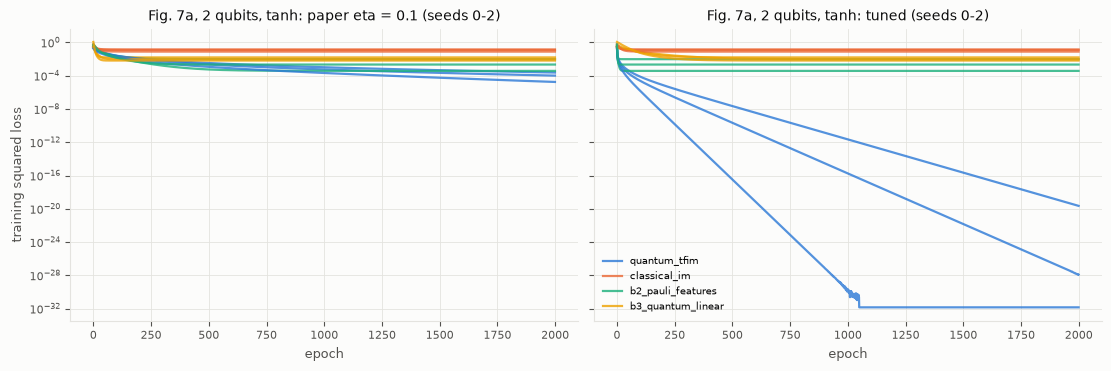

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True, layout="constrained")
for axis, protocol in zip(axes, ("paper eta = 0.1", "tuned")):
    for seed in (0, 1, 2):
        _, history = live[(protocol, seed)]
        for column in history.columns[1:]:
            name = column.removesuffix("_train_loss")
            axis.plot(history["epoch"], history[column], color=ROLE_COLOUR[role(name)], alpha=0.8,
                      label=f"{name}" if seed == 0 else None)
    axis.set_yscale("log")
    axis.set_xlabel("epoch")
    axis.set_title(f"Fig. 7a, 2 qubits, tanh: {protocol} (seeds 0-2)")
axes[0].set_ylabel("training squared loss")
axes[1].legend(loc="lower left", fontsize=7)
plt.show()

**Reproducibility check.** The tuned runs above must agree with the
stored stage-B sweep (`p5_final_v1`, separate processes, single-threaded
BLAS). Values far below 1e-20 are round-off and are compared only as
"below 1e-20".

In [7]:
stored = seed_table.query("sweep == 'p5_final_v1' and config == 'p5_final_fig7_tanh_2q' and metric == 'test_mse'")
mismatches = 0
for row in stored[stored.seed <= 2].itertuples():
    live_value = live_table[(live_table.protocol == "tuned") & (live_table.seed == row.seed)
                            & (live_table.model == row.model)]["test MSE"].item()
    both_roundoff = live_value < 1e-20 and row.value < 1e-20
    agree = both_roundoff or abs(math.log10(live_value) - math.log10(row.value)) < 1e-6
    mismatches += not agree
print("live vs stored stage-B values:", "all agree" if mismatches == 0 else f"{mismatches} disagree")
assert mismatches == 0

live vs stored stage-B values: all agree


**Teacher recovery.** At its tuned rate the quantum neuron's test MSE is
round-off. Here is why: its parameters converge to the teacher's
coefficients ζ. The target is generated by the quantum model's own class.

In [8]:
for seed in (0, 1, 2):
    metrics, _ = live[("tuned", seed)]
    zeta = np.array(metrics["target"]["zeta"])
    theta = np.array(metrics["models"]["quantum_tfim"]["final_parameters"])
    print(f"seed {seed}: teacher zeta {np.round(zeta, 4)}  learned theta {np.round(theta, 4)}  max |theta - zeta| = {np.abs(theta - zeta).max():.1e}")

seed 0: teacher zeta [ 0.5478 -0.9209 -1.8361 -1.9339]  learned theta [ 0.5478 -0.9209 -1.8361 -1.9339]  max |theta - zeta| = 1.5e-13
seed 1: teacher zeta [ 0.0473  1.8019 -1.4234  1.7946]  learned theta [ 0.0473  1.8019 -1.4234  1.7946]  max |theta - zeta| = 3.0e-09
seed 2: teacher zeta [-0.9536 -0.806   1.2569 -1.6323]  learned theta [-0.9536 -0.806   1.2569 -1.6323]  max |theta - zeta| = 1.3e-15


**Observation.**
- **At η = 0.1, on this 2-qubit task**, the quantum neuron already beats
  both the commuting model (B1) and the classical neuron on the same
  features (B2), by 1–3 decades. At 7 qubits, Phase 3 found it tied with
  B2 at this rate (`LOG.md`).
- **Tuned:** the quantum neuron recovers the teacher's coefficients
  exactly, and its test MSE drops to round-off. B2, B3 and B1 stay at
  1e-3 to 1e-1.
- **The live runs reproduce the stored sweep exactly.**

**Inference.** The paper's learning rate under-trains the quantum neuron.
The tuned "win" is the student recovering a teacher of its own form.

**Remaining uncertainty.** Three seeds and one task here; Sections 7–9
use all 10 seeds and all tasks.

**Claim impact.** C4 holds on this task, but its explanation is now in
question (Section 9).

## 7. Headline reproduction result

Paper values against the 10-seed reproduction under the authors' protocol
(`paper_seeds_v1` sweep).
- **Figs. 7 and 9:** final training loss.
- **Table II:** test accuracy (linear rule).
- **Paper values:** released CSVs (Fig. 7), Table II, and pixel readings of
  the Fig. 9 image (the paper gives no numbers).

"Within seed range" means the paper value lies inside our 10-seed min–max.

In [9]:
placement = pd.read_csv(RESULTS / "paper_seeds_v1_paper_placement.csv")
keep = placement[((placement.config.str.startswith("fig8")) & (placement.paper_source == "Table II"))
                 | ((~placement.config.str.startswith("fig8")) & (placement.metric == "train_loss"))].copy()
keep["task"] = keep.config.str.removesuffix("_original")
keep["delta"] = np.where(keep.metric.str.contains("accuracy"),
                         100 * (keep.our_median - keep.paper_value),
                         np.log10(keep.our_median) - np.log10(keep.paper_value))
keep["delta unit"] = np.where(keep.metric.str.contains("accuracy"), "points", "decades")
display(keep[["task", "model", "paper_value", "our_median", "our_min", "our_max", "delta", "delta unit", "inside_our_range"]]
        .rename(columns={"inside_our_range": "within seed range"}).reset_index(drop=True))

,task,model,paper_value,our_median,our_min,our_max,delta,delta unit,within seed range
0,fig7_tanh_2q,quantum_tfim,3.822e-05,1.247e-05,1.033e-16,3.203e-04,-0.487,decades,True
1,fig7_tanh_2q,classical_im,1.173e-02,8.256e-02,3.196e-02,1.338e-01,0.848,decades,False
2,fig7_tanh_7q,quantum_tfim,7.409e-04,1.188e-03,6.524e-04,2.053e-03,0.205,decades,True
3,fig7_tanh_7q,classical_im,1.634e-01,1.432e-01,1.113e-01,1.964e-01,-0.057,decades,True
4,fig7_softplus_2q,quantum_tfim,1.083e-04,3.926e-03,1.200e-04,2.159e-02,1.559,decades,False
5,fig7_softplus_2q,classical_im,8.167e-01,1.591e-01,3.750e-02,7.050e+00,-0.711,decades,True
6,fig7_softplus_7q,quantum_tfim,5.170e+00,7.477e+00,6.960e-01,1.943e+02,0.160,decades,True
7,fig7_softplus_7q,classical_im,1.620e+01,6.223e+01,5.240e+00,1.079e+03,0.584,decades,True
8,fig8_logistic_2q,quantum_heisenberg,9.520e-01,9.610e-01,9.460e-01,9.760e-01,0.900,points,True
9,fig8_logistic_2q,classical_fcim,6.400e-01,7.050e-01,6.320e-01,7.600e-01,6.500,points,True


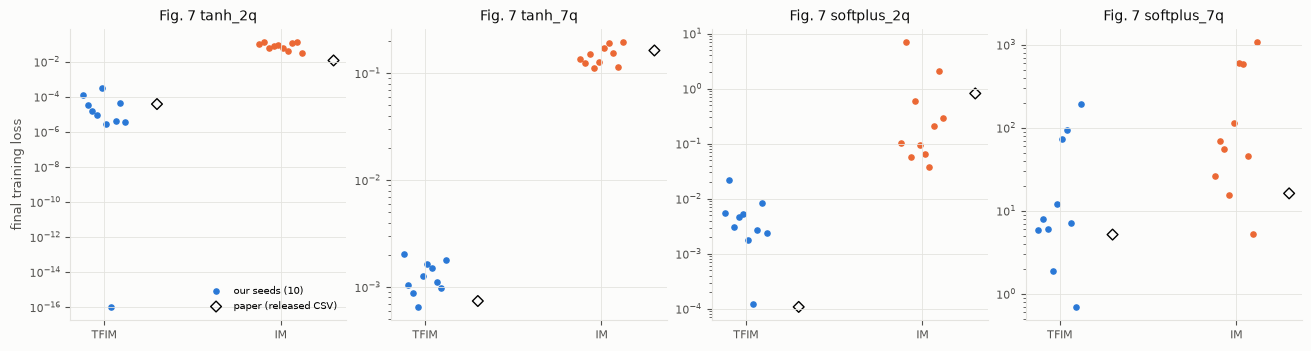

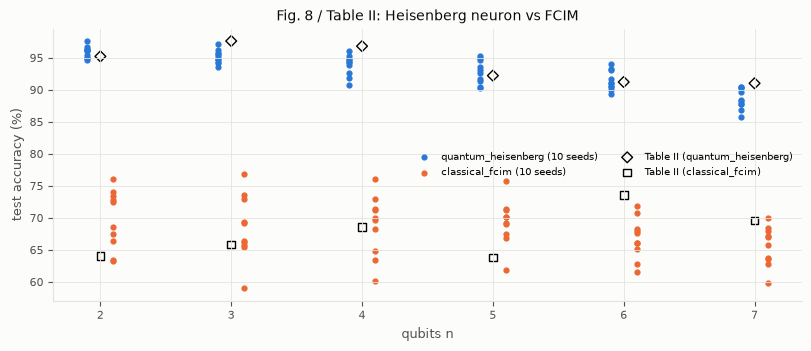

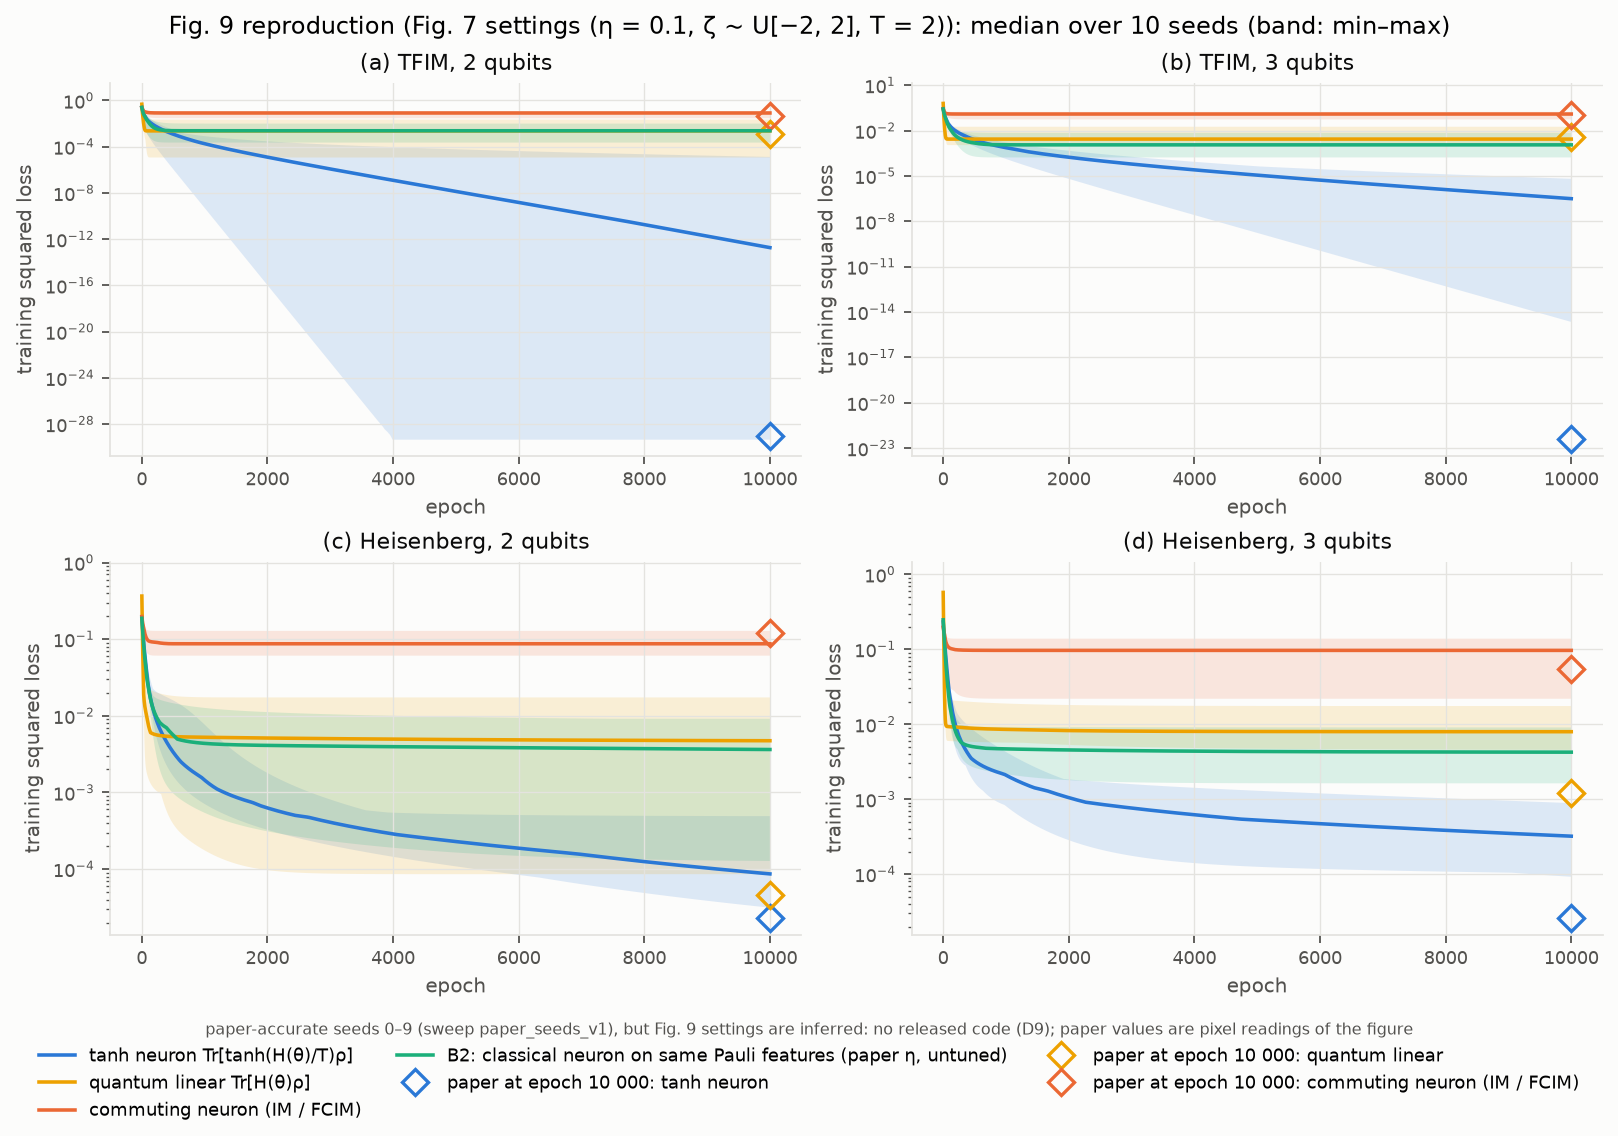

In [10]:
paper = seed_table.query("sweep == 'paper_seeds_v1'")
panels = [("fig7_tanh_2q_original", "train_loss"), ("fig7_tanh_7q_original", "train_loss"),
          ("fig7_softplus_2q_original", "train_loss"), ("fig7_softplus_7q_original", "train_loss")]
fig, axes = plt.subplots(1, 4, figsize=(13, 3.4), layout="constrained")
for axis, (config, metric) in zip(axes, panels):
    for position, model in enumerate(("quantum_tfim", "classical_im")):
        values = paper.query("config == @config and model == @model and metric == @metric").value
        axis.scatter(np.full(len(values), position) + np.linspace(-0.12, 0.12, len(values)), values,
                     color=ROLE_COLOUR[role(model)], s=14, label="our seeds (10)" if position == 0 else None)
        reference = placement.query("config == @config and model == @model and metric == @metric")
        axis.scatter([position + 0.3], reference.paper_value, marker="D", facecolor="none", edgecolor="black",
                     s=30, label="paper (released CSV)" if position == 0 else None)
    axis.set_yscale("log")
    axis.set_xticks([0, 1], ["TFIM", "IM"])
    axis.set_title(config.removesuffix("_original").replace("fig7_", "Fig. 7 "))
axes[0].set_ylabel("final training loss")
axes[0].legend(fontsize=7, loc="lower right")
plt.show()

accuracy = paper[(paper.metric == "test_accuracy_linear") & paper.config.str.startswith("fig8_logistic")
                 & paper.config.str.endswith("original")]
fig, axis = plt.subplots(figsize=(8, 3.4), layout="constrained")
for model, offset in (("quantum_heisenberg", -0.1), ("classical_fcim", 0.1)):
    sub = accuracy.query("model == @model")
    n = sub.config.str.extract(r"(\d)q")[0].astype(int)
    axis.scatter(n + offset, 100 * sub.value, color=ROLE_COLOUR[role(model)], s=12, label=f"{model} (10 seeds)")
for model, marker in (("quantum_heisenberg", "D"), ("classical_fcim", "s")):
    ref = placement.query("paper_source == 'Table II' and model == @model")
    axis.scatter(ref.config.str.extract(r"(\d)q")[0].astype(int), 100 * ref.paper_value, marker=marker,
                 facecolor="none", edgecolor="black", s=30, label=f"Table II ({model})")
axis.set_xlabel("qubits n")
axis.set_ylabel("test accuracy (%)")
axis.set_title("Fig. 8 / Table II: Heisenberg neuron vs FCIM")
axis.legend(fontsize=7, ncol=2)
plt.show()
display(Image(filename=str(RESULTS / "figures" / "fig9_reproduction_original.png"), width=900))

**Observation.**
- **Ordering:** every panel reproduces the paper's ordering, quantum
  better than commuting, at every seed.
- **Fig. 7:** paper values lie inside our seed range except two (tanh 2q
  IM, softplus 2q TFIM, both just outside).
- **Table II:** values lie within or a few points from our range. Table II
  is a single run and differs from the authors' own CSVs.
- **Fig. 9:** the ordering tanh < linear < commuting holds. The absolute
  values do not reproduce (the paper's tanh floors are 1e-30 and 1e-23),
  and neither does the 2-qubit Heisenberg exception.

**Inference.** The paper's experiments are reproducible in trend and
mostly in value. The Fig. 9 settings cannot be identified from one
unseeded run (two sensitivity variants were tried; see `LOG.md`).

**Remaining uncertainty.** Fig. 9's unstated settings.

**Claim impact.** C4 and C5 are reproduced against the paper's baselines.
C6 is reproduced in ordering only; its 2-qubit Heisenberg explanation is
contradicted.

## 8. Fair baseline comparison

The paper's baselines (IM, FCIM) only see Z measurements, so its
comparisons mix "quantization" with "measurement access". This section
compares the quantum neuron with B2 instead. The plan was declared in
Phase 1 and frozen before any comparison run (`LOG.md`, "Phase 5
Comparison Plan").

Fairness of the quantum neuron vs B2, dimension by dimension:

| Dimension | Status |
|---|---|
| Information and inputs | **Matched.** The same Pauli observables H_j: B2 measures ⟨H_j⟩, the quantum neuron applies tanh to Σθ_j H_j before measuring |
| Parameter count | **Matched** (J for both; B1 as in the paper; B4 has more, 16–211) |
| Training data | **Matched** (the same 80 % of the paper's training states) |
| Optimization steps | **Matched** (full-batch GD, the paper's epoch budget) |
| Tuning budget | **Matched**: the same 9-value learning-rate grid, chosen per model on the selection split with seeds 0–2 |
| Compute and wall time | **Not matched**: the quantum neuron needs exact simulation, O(d³) per step (35.6 s vs 0.12 s at 7 qubits) |
| Evaluation protocol | **Matched**: 500 held-out states, seeds 0–9, paired Wilcoxon |

**Pre-declared rule.** A claim is SUPPORTED only if the quantum neuron
beats tuned B2 in every task of the claim.

In [11]:
comparison = json.loads((RESULTS / "p5_comparison.json").read_text())
primary = pd.DataFrame([row for row in comparison["comparisons"]
                        if row["metric"] in ("validation_mse", "validation_accuracy_linear") and "median_advantage" in row])
primary = primary[primary.other_model.isin(["b2_pauli_features", "correlation_tanh"])]
display(primary[["claim", "task", "other_model", "median_advantage", "min_advantage", "max_advantage", "seeds_favouring", "wilcoxon_p", "verdict"]]
        .rename(columns={"median_advantage": "median advantage (dec / pts)", "seeds_favouring": "seeds favouring quantum"}).reset_index(drop=True))
display(pd.DataFrame({claim: {"outcome": entry["outcome"], "tasks won": f"{entry['tasks_won']}/{entry['tasks']}"}
                      for claim, entry in comparison["claim_outcomes"].items()}).T)

,claim,task,other_model,median advantage (dec / pts),min_advantage,max_advantage,seeds favouring quantum,wilcoxon_p,verdict
0,C4,fig7_tanh_2q,b2_pauli_features,27.821,4.140,29.179,10,0.002,supported
1,C4,fig7_tanh_7q,b2_pauli_features,21.375,11.885,28.587,10,0.002,supported
2,C4,fig7_softplus_2q,b2_pauli_features,1.605,0.761,2.984,10,0.002,supported
3,C4,fig7_softplus_7q,b2_pauli_features,1.938,1.716,2.282,10,0.002,supported
4,C5,fig8_logistic_2q,b2_pauli_features,-3.100,-5.000,-1.200,0,0.002,not_supported
5,C5,fig8_logistic_3q,b2_pauli_features,-3.600,-6.400,-1.000,0,0.002,not_supported
6,C5,fig8_logistic_4q,b2_pauli_features,-4.700,-7.600,-3.000,0,0.002,not_supported
7,C5,fig8_logistic_5q,b2_pauli_features,-5.300,-8.600,-2.400,0,0.002,not_supported
8,C5,fig8_logistic_6q,b2_pauli_features,-5.400,-9.200,-3.000,0,0.002,not_supported
9,C5,fig8_logistic_7q,b2_pauli_features,-5.300,-7.000,-3.800,0,0.002,not_supported


,outcome,tasks won
C4,SUPPORTED,4/4
C5,UNSUPPORTED,0/6
C6,SUPPORTED,4/4
MerLin,SUPPORTED,3/3


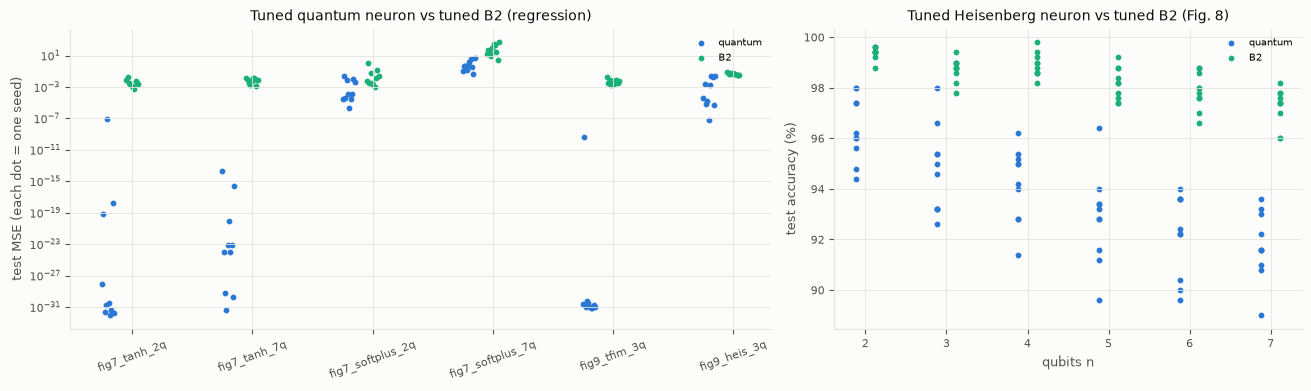

Learning rates selected for B2 on Fig. 8 (largest grid value is 100):


,task,model,selected learning rate
0,fig8_logistic_2q,b2_pauli_features,100.0
1,fig8_logistic_3q,b2_pauli_features,100.0
2,fig8_logistic_4q,b2_pauli_features,100.0
3,fig8_logistic_5q,b2_pauli_features,100.0
4,fig8_logistic_6q,b2_pauli_features,100.0
5,fig8_logistic_7q,b2_pauli_features,100.0


In [12]:
final = seed_table.query("sweep == 'p5_final_v1'")
tasks = ["fig7_tanh_2q", "fig7_tanh_7q", "fig7_softplus_2q", "fig7_softplus_7q", "fig9_tfim_3q", "fig9_heis_3q"]
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), layout="constrained", gridspec_kw={"width_ratios": [3, 2]})
for index, task in enumerate(tasks):
    config_name = "p5_final_" + task
    sub = final.query("config == @config_name and metric == 'test_mse'")
    for offset, model in ((-0.2, None), (0.0, "b2_pauli_features")):
        name = model or sub.model[sub.model.str.startswith("quantum") & ~sub.model.str.endswith("_linear")].iloc[0]
        values = sub.query("model == @name").value
        axes[0].scatter(np.full(10, index + offset) + np.linspace(-0.05, 0.05, 10), values,
                        color=ROLE_COLOUR[role(name)], s=10, label=role(name) if index == 0 else None)
axes[0].set_yscale("log")
axes[0].set_xticks(range(len(tasks)), tasks, rotation=20)
axes[0].set_ylabel("test MSE (each dot = one seed)")
axes[0].set_title("Tuned quantum neuron vs tuned B2 (regression)")
axes[0].legend(fontsize=7)
for n in range(2, 8):
    config_name = f"p5_final_fig8_logistic_{n}q"
    sub = final.query("config == @config_name and metric == 'test_accuracy_linear'")
    for offset, model in ((-0.12, "quantum_heisenberg"), (0.12, "b2_pauli_features")):
        values = 100 * sub.query("model == @model").value
        axes[1].scatter(np.full(10, n + offset), values, color=ROLE_COLOUR[role(model)], s=10,
                        label=role(model) if n == 2 else None)
axes[1].set_xlabel("qubits n")
axes[1].set_ylabel("test accuracy (%)")
axes[1].set_title("Tuned Heisenberg neuron vs tuned B2 (Fig. 8)")
axes[1].legend(fontsize=7)
plt.show()

selection = json.loads((RESULTS / "p5_selection.json").read_text())
edge = [{"task": row["task"], "model": row["model"], "selected learning rate": row["selected_learning_rate"]}
        for row in selection["qubit"] if row["model"] == "b2_pauli_features" and row["task"].startswith("fig8")]
print("Learning rates selected for B2 on Fig. 8 (largest grid value is 100):")
display(pd.DataFrame(edge))

**Observation.**
- **Regression (C4, C6).** The tuned quantum neuron beats tuned B2 in every
  task, at every seed except one (Fig. 9 Heisenberg 2q, 9/10 seeds). The
  median margin is 20–29 decades where it reaches round-off (Fig. 7 tanh,
  Fig. 9 TFIM) and 1.6–5.8 decades elsewhere.
- **Classification (C5).** Tuned B2 beats the tuned Heisenberg neuron at
  every n and every seed, by 3.1–5.4 points (97.4–99.4 % vs 91.6–96.1 %).
  B2's learning rate sits at the top of the grid (100), so its result is a
  lower bound.

**Inference.**
- **C5 reverses.** In the authors' code the labels are sign Tr[H*ρ], a
  linear function of exactly B2's features. B2 (logistic regression) is
  then the correctly specified model.
- **C4 and C6 hold, but the margins track whether the target can be fitted
  exactly** (Section 9), not the size of the system.

**Remaining uncertainty.** Learning rates were chosen with 3 seeds, and the
selection split is tiny at 2 qubits (3 states). Fig. 8 was run only with
the code label rule.

**Claim impact.**
- C4: supported against the fair baseline, with a confounder.
- C5: contradicted by the fair baseline.
- C6: supported against B2 and B3, with the same confounder.

## 9. Controls and ablations

Three controls test the paper's explanation ("quantization of
non-commuting Hamiltonians helps learning") against alternatives:

1. **Classical data (C8, E8).** If quantization were the cause, its
   advantage over the commuting model should vanish when the training
   states are classical (computational basis).
2. **Linear vs nonlinear (C6).** Is it the activation of the operator that
   helps? Tanh is compared with the tuned quantum linear model B3.
3. **Teacher inside the model class.** The paper's teacher is tanh of a
   Hamiltonian from the student's own term set. Learning was measured
   with students that differ from the teacher (E16b, paper protocol):
   does learning still happen?

In [13]:
e8 = pd.DataFrame(json.loads((RESULTS / "e8_classical_data_summary.json").read_text())["comparisons"])
e8 = e8[e8.metric.isin(["validation_mse", "validation_accuracy_linear"])]
display(e8[["config", "metric", "median_advantage", "seeds_favouring", "wilcoxon_p", "verdict"]]
        .rename(columns={"median_advantage": "quantum - commuting (dec / pts)"}).reset_index(drop=True))

linear = pd.DataFrame([row for row in comparison["comparisons"]
                       if row["claim"] == "C6" and row["metric"] == "validation_mse" and row["other_model"].endswith("_linear")])
print("C6 ablation: tuned tanh neuron vs tuned quantum linear model (test MSE, decades)")
display(linear[["task", "median_advantage", "seeds_favouring", "verdict"]].reset_index(drop=True))

e16 = pd.DataFrame(json.loads((RESULTS / "e16_teacher_summary.json").read_text())["improvement_over_initialization"])
e16["student"] = e16.student.map({"matched": "same term set as teacher", "other": "different term set"})
print("E16b: log10(final / initial test MSE) at the paper's protocol (more negative = learned more)")
display(e16[["student", "n_qubits", "count", "median_log10_final_over_initial"]])

,config,metric,quantum - commuting (dec / pts),seeds_favouring,wilcoxon_p,verdict
0,e8_fig7_tanh_2q_basis,validation_mse,-0.004,5,0.770,tie
1,e8_fig7_tanh_2q_haar,validation_mse,1.203,10,0.002,supported
2,e8_fig7_tanh_7q_basis,validation_mse,-0.061,2,0.232,tie
3,e8_fig7_tanh_7q_haar,validation_mse,0.205,10,0.002,supported
4,e8_fig8_logistic_3q_basis,validation_accuracy_linear,0.400,5,0.227,tie
5,e8_fig8_logistic_3q_haar,validation_accuracy_linear,11.300,10,0.002,supported
6,e8_fig8_logistic_5q_basis,validation_accuracy_linear,1.000,9,0.004,supported
7,e8_fig8_logistic_5q_haar,validation_accuracy_linear,10.200,10,0.002,supported
8,e8_fig8_logistic_7q_basis,validation_accuracy_linear,0.900,8,0.008,tie
9,e8_fig8_logistic_7q_haar,validation_accuracy_linear,18.600,10,0.002,supported


C6 ablation: tuned tanh neuron vs tuned quantum linear model (test MSE, decades)


,task,median_advantage,seeds_favouring,verdict
0,fig9_tfim_2q,28.499,10,supported
1,fig9_tfim_3q,28.080,10,supported
2,fig9_heis_2q,6.168,8,supported
3,fig9_heis_3q,2.135,10,supported


E16b: log10(final / initial test MSE) at the paper's protocol (more negative = learned more)


,student,n_qubits,count,median_log10_final_over_initial
0,same term set as teacher,3,45,-0.554
1,same term set as teacher,5,45,-0.206
2,same term set as teacher,7,45,-0.252
3,different term set,3,360,-0.069
4,different term set,5,360,-0.064
5,different term set,7,360,-0.044


**Observation.**
- **C8 holds.** With basis-state training data the quantum and commuting
  models tie (one Fig. 8 cell sits exactly at the 1-point tolerance). With
  Haar (quantum) data the quantum model wins.
- **The nonlinearity matters.** Tuned tanh beats the tuned linear model in
  every Fig. 9 panel.
- **Only the student that matches the teacher learns.** At the paper's
  protocol, a student with the teacher's own term set reduces its test
  error by 0.2–0.55 decades. A student with any other term set reduces it
  by only 0.04–0.07 decades.

**Inference.** The quantum neuron's large wins come from the target being
exactly representable by it: a well-specified model against misspecified
ones. That is a credible alternative to "quantization helps learning", and
the paper's experiments cannot tell the two apart.

**Remaining uncertainty.** The decisive control was not run with tuned
learning rates: a teacher outside every model's class (for example, a
Heisenberg teacher for a TFIM student).

**Claim impact.** The paper's explanation for C4 and C6 is weakened, not
refuted. C8 is reproduced.

## 10. Robustness and uncertainty

- **Learning rate, temperature and finite shots (E9).** The quantum vs
  commuting ranking was re-tested over η ∈ {0.03, 0.1, 0.3} and
  T ∈ {0.5, 1, 2, 4}, and with gradients estimated from 10–1000
  measurement shots (the paper's Algorithms 1 and 2).
- **Seed spread.** Single-run paper values can sit anywhere in a wide
  seed distribution (Section 7).
- **Trainability (E10, E11).** Do gradients vanish as qubits are added?

E9 grid: quantum beats commuting in 72/72 (eta, T, metric) cells, seeds favouring quantum: min 10/10


,shots per state and parameter,quantum final loss (median),exact-gradient loss,advantage over commuting (dec),seeds
0,10,7.344e-04,1.247e-05,1.981,10/10
1,100,7.101e-05,1.247e-05,3.128,10/10
2,1000,1.255e-05,1.247e-05,3.727,10/10


training states,code,haar
n,,
2,3.595,2.201
3,2.615,1.578
4,2.466,0.923
5,2.137,0.609
6,2.125,0.411
7,2.069,0.287
8,2.009,0.198


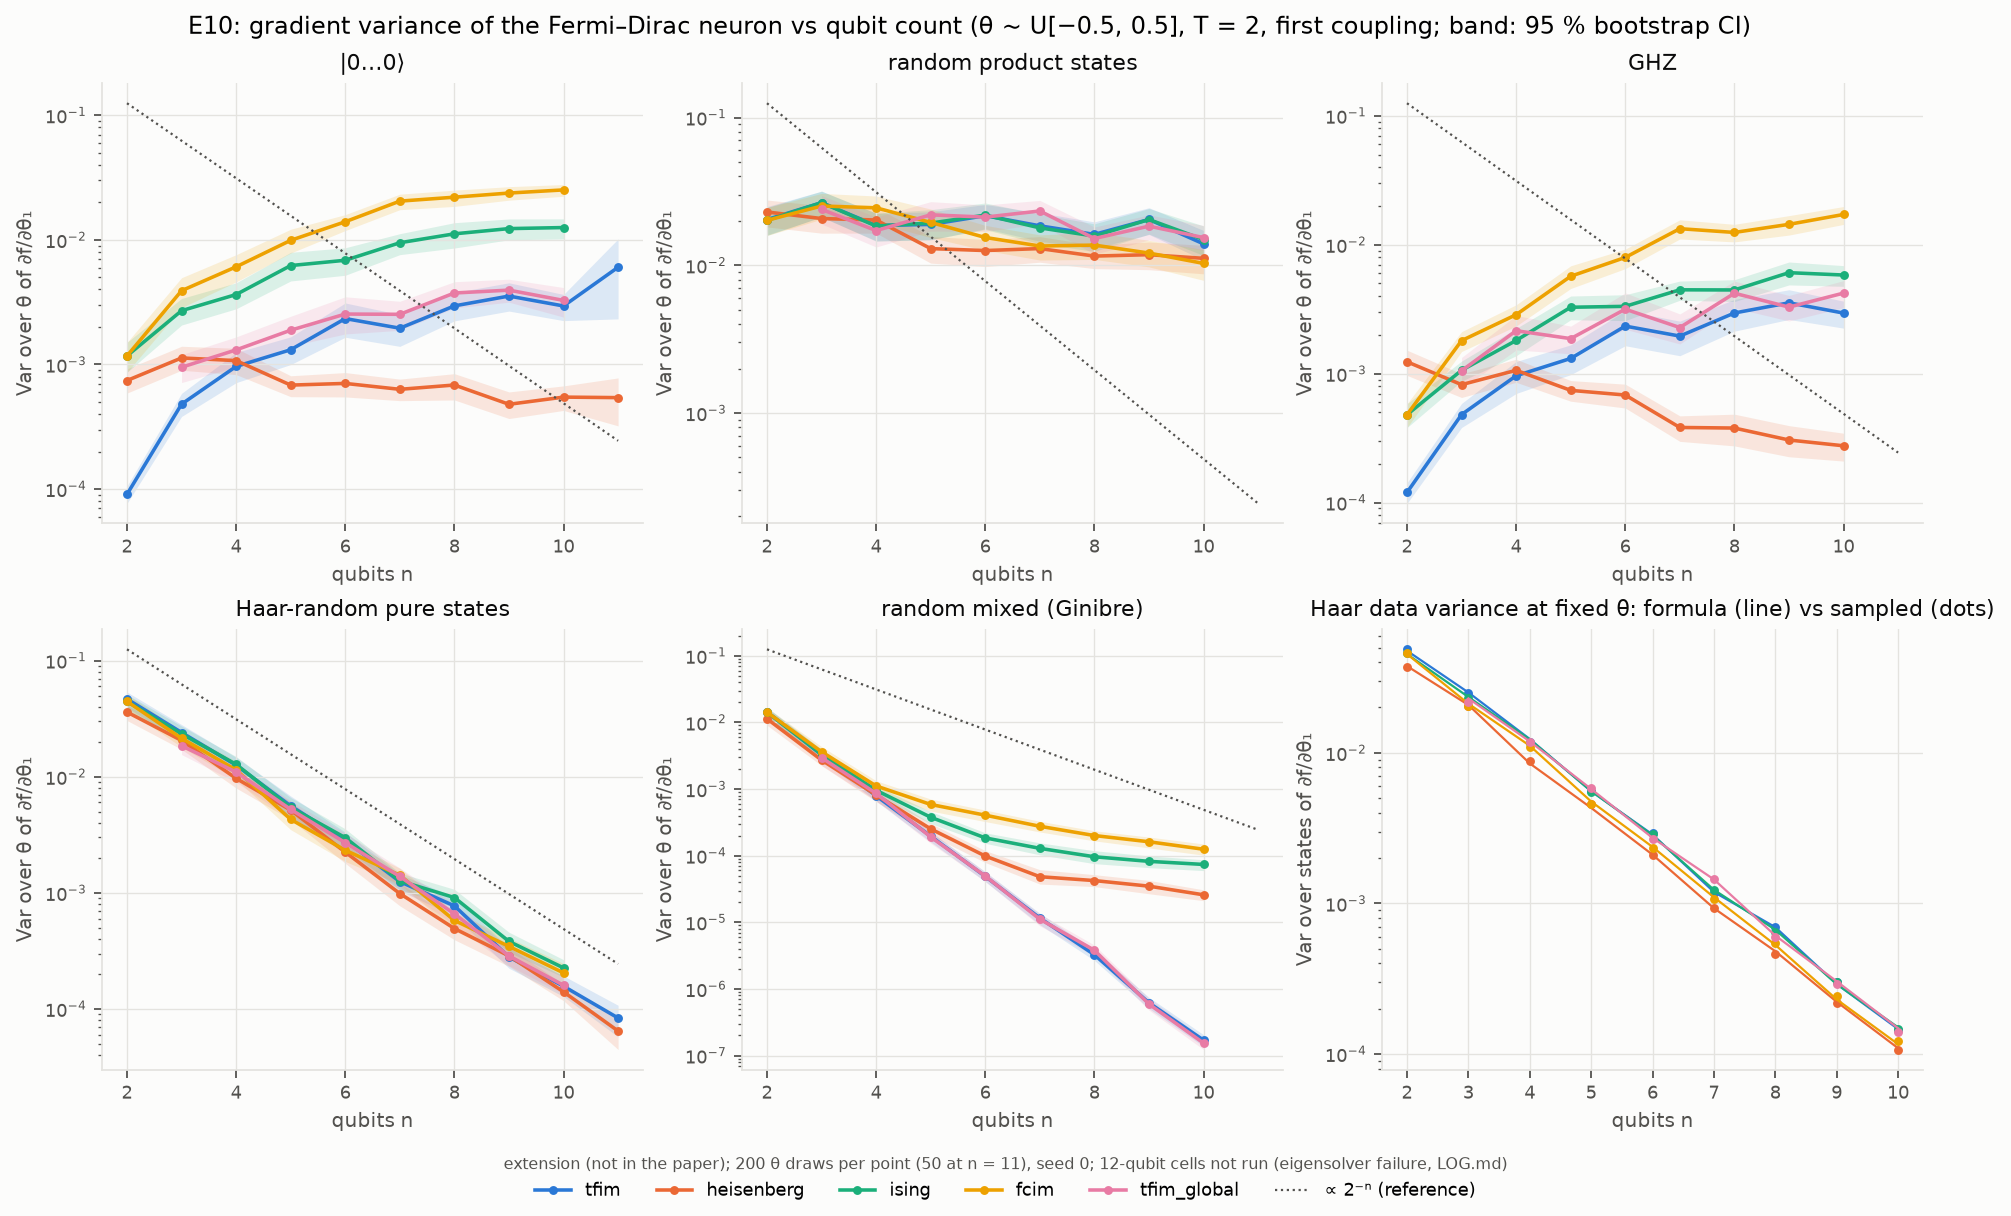

In [14]:
e9 = json.loads((RESULTS / "e9_robustness_summary.json").read_text())
grid = pd.DataFrame(e9["grid"])
print(f"E9 grid: quantum beats commuting in {sum(grid.verdict == 'supported')}/{len(grid)} (eta, T, metric) cells, "
      f"seeds favouring quantum: min {grid.seeds_favouring.min()}/10")
shots = pd.DataFrame([{"shots per state and parameter": row["shots"],
                       "quantum final loss (median)": row["quantum_tfim"]["train_loss_median"],
                       "exact-gradient loss": row["quantum_tfim"]["exact_gradient_train_loss_median"],
                       "advantage over commuting (dec)": row["advantage"]["median_advantage"],
                       "seeds": f"{row['advantage']['seeds_favouring']}/10"} for row in e9["finite_shots"]])
display(shots)

e11 = pd.DataFrame([{"n": row["n_qubits"], "training states": row["state_set"],
                     "quantum advantage (dec, median)": row["quantum_advantage_decades_median"],
                     "seeds favouring quantum": row["seeds_favouring_quantum"]}
                    for row in json.loads((RESULTS / "e11_training_vs_n_summary.json").read_text())["rows"]])
display(e11.pivot(index="n", columns="training states", values="quantum advantage (dec, median)"))
display(Image(filename=str(RESULTS / "figures" / "e10_gradient_variance_vs_n.png"), width=900))

**Observation.**
- **Ranking under E9.** The ranking against the commuting model holds in
  all 72 (η, T, metric) cells.
- **Finite shots.** 1000 measurement shots train as well as exact
  gradients.
- **Haar training states (E10, E11).**
  - Gradient variances fall ≈ 2⁻ⁿ for every Hamiltonian family, commuting
    or not.
  - The quantum model's advantage shrinks from +2.2 to +0.2 decades by
    8 qubits.
- **Structured states (E10, E11).** Gradients do not decay exponentially,
  and the advantage stays at 2–3.6 decades.

**Inference.**
- The comparison with the paper's baseline is robust.
- Trainability is limited by the input data (Haar states concentrate), not
  by the Hamiltonian.

**Remaining uncertainty.**
- The size range is small (n ≤ 8 for training, n ≤ 11 for gradients).
- The two 12-qubit cells failed.

**Claim impact.** No change to C4–C6. This is an extension beyond the
paper.

## 11. Photonic assessment (MerLin adaptation)

**Why it maps exactly.** The paper's continuous-variable neuron (Sec. V)
applies the activation to a quadratic bosonic Hamiltonian. Take a passive
(photon-number-conserving) one, H = Σ h_ij a_i†a_j with h = U† diag(ε) U.
Its N-photon eigenstates are Fock states of the modes that the
interferometer U reaches, so

$$\mathrm{Tr}[\tanh(H/T)\,\rho] = \sum_{\mathbf n} p_U(\mathbf n)\,\tanh(\boldsymbol\varepsilon\cdot\mathbf n/T),$$

where p_U is the photon-number distribution after U.

**The photonic neuron.** That is:
- one trainable MerLin mesh;
- photon-number-resolving detection;
- a classical tanh of the energies.

The commuting limit (no mesh) is a classical neuron on photon counts.
Status: `PARTIAL_MERLIN_TRANSLATION`. The paper's qubit tasks need ZZ
interactions, which linear optics cannot provide.

**Live check.** The MerLin model equals dense Fock-space
diagonalization.

In [15]:
rng = np.random.default_rng(1)
n_modes, n_photons, temperature = 4, 2, 2.0
neuron = ph.MerlinPassiveNeuron(n_modes, n_photons, "tanh", temperature)
theta = np.concatenate([rng.uniform(0, 2 * np.pi, neuron.n_phases), rng.uniform(-2, 2, n_modes)])
states = ph.haar_full_states(len(ph.fock_basis(n_modes, n_photons)), 5, rng)
merlin_output = neuron.outputs(theta, ph.PhotonicDataset(states, np.zeros(5)))
unitary = neuron.unitary()
h = unitary.conj().T @ np.diag(theta[neuron.n_phases:]) @ unitary
values, vectors = np.linalg.eigh(ph.fock_operator(h, n_photons))
dense = np.real(np.einsum("mi,ij,mj->m", states.conj(), vectors @ np.diag(np.tanh(values / temperature)) @ vectors.conj().T, states))
print(f"MerLin (mesh + PNR + tanh) vs dense Fock-space diagonalization, 5 random 2-photon states: max |difference| = {np.abs(merlin_output - dense).max():.1e}")

MerLin (mesh + PNR + tanh) vs dense Fock-space diagonalization, 5 random 2-photon states: max |difference| = 3.6e-16


,"(N photons, m modes)",paper GD: photonic - correlation (dec),tuned Adam: photonic - correlation (dec),tuned: seeds favouring photonic,tuned photonic test MSE (median),tuned correlation test MSE (median)
0,"(2, 4)",0.067,0.158,10/10,5.621e-02,0.093
1,"(3, 6)",-0.449,0.650,10/10,1.942e-03,0.009
2,"(4, 8)",-1.084,1.044,10/10,9.264e-05,0.001


Hardware ablations (photonic neuron, median log10 of test MSE relative to exact PNR; paper GD runs):


readout,shots100,shots1000,threshold,unbunched
config,,,,
p4_learn_m4_n2_haar,0.022,0.002,0.003,0.110
p4_learn_m6_n3_haar,0.029,0.001,0.053,0.126
p4_learn_m8_n4_haar,0.033,0.005,0.100,0.123


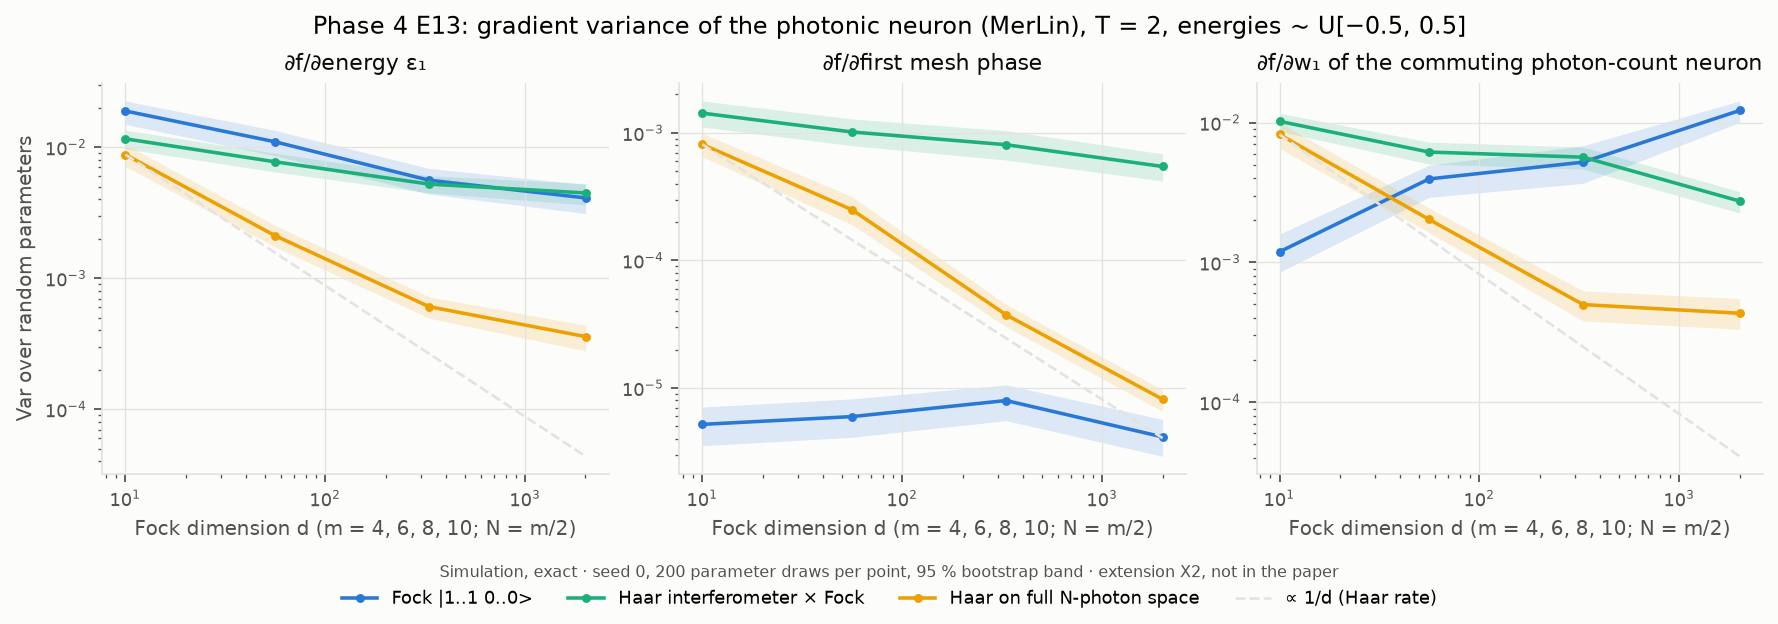

In [16]:
p4 = pd.DataFrame(json.loads((RESULTS / "p4_learning_summary.json").read_text())["comparisons"])
p4 = p4.query("arm == 'haar' and metric == 'validation_mse' and other_model == 'correlation_tanh'")
photonic_final = seed_table.query("sweep == 'p5_photonic_final_v1' and metric == 'test_mse'")
rows = []
for m, n in ((4, 2), (6, 3), (8, 4)):
    stored = p4[(p4.n_modes == m) & (p4.n_photons == n)].iloc[0]
    config_name = f"p5_phfinal_m{m}_n{n}"
    sub = photonic_final.query("config == @config_name")
    neuron_values = sub.query("model == 'photonic_tanh'").set_index("seed").value
    classical_values = sub.query("model == 'correlation_tanh'").set_index("seed").value
    differences = np.log10(classical_values) - np.log10(neuron_values)
    rows.append({"(N photons, m modes)": f"({n}, {m})",
                 "paper GD: photonic - correlation (dec)": stored.median_advantage,
                 "tuned Adam: photonic - correlation (dec)": np.median(differences),
                 "tuned: seeds favouring photonic": f"{int((differences > 0).sum())}/10",
                 "tuned photonic test MSE (median)": neuron_values.median(),
                 "tuned correlation test MSE (median)": classical_values.median()})
display(pd.DataFrame(rows))

ablation = pd.DataFrame(json.loads((RESULTS / "p4_learning_summary.json").read_text())["readout_ablations"])
ablation = ablation[ablation.config.str.endswith("haar")]
print("Hardware ablations (photonic neuron, median log10 of test MSE relative to exact PNR; paper GD runs):")
display(ablation.pivot(index="config", columns="readout", values="median_log10_ratio_to_pnr"))
display(Image(filename=str(RESULTS / "figures" / "p4_trainability.png"), width=900))

**Observation.**
- **Exactness.** The MerLin model is exact (≈ 1e-16).
- **Learning, paper GD.** Under the paper's plain gradient descent, the
  classical correlation neuron (B2 counterpart) wins at (3, 6) and (4, 8).
- **Learning, tuned Adam.** With every photonic model on Adam, tuned the
  same way, the photonic neuron wins at every size and every seed.
- **Hardware costs.** Threshold detectors and collision-free postselection
  cost ≤ 0.13 decade; 1000 photon-counting shots per state are as good as
  exact.
- **Gradients.** With linear-optics inputs the gradient variance decays
  more slowly than 1/d.

**Inference.** The photonic version shows the same pattern as the qubit
neuron: it wins when trained well, against a teacher of its own form. The
Phase 4 loss was an optimizer handicap of the mesh phases.

**Remaining uncertainty.**
- Simulation only, with lossless and indistinguishable photons.
- The same teacher-in-class confounder.
- One seed for the trainability study.

**Claim impact.** The adaptation reproduces the qualitative structure. It
gives no evidence of photonic advantage beyond the confounder.

## 12. Limitations

**Deviations, reductions and omissions, with their likely impact:**

| Item | Kind | Likely impact on the conclusions |
|---|---|---|
| 10 seeds instead of the paper's single unseeded run | deviation | Strengthens the evidence. Paper values can only be placed inside or outside our seed range, not matched exactly (Section 7) |
| Code protocol used here (paper-text protocol also run, `LOG.md`) | deviation | Low. Both protocols give the same rankings vs the paper's baselines; absolute values differ (paper text: larger Fig. 7 softplus margins) |
| Fig. 9 settings inferred (no released code) | deviation | High for Fig. 9 absolute values (not reproducible); none for the ordering, which holds under both sensitivity variants |
| Exact gradients instead of sampled estimators | deviation | Low. With 1000 shots, training matches exact gradients (Section 10); fewer shots raise the final loss but keep the ranking |
| CPU simulation in float64, no QPU or noise | deviation | Losses near 1e-30 are round-off, not physical. Hardware noise would raise the floors and could shrink the round-off-level wins (Sections 6, 8) |
| E10 partial (two 12-qubit cells failed) | incomplete | Low. The barren-plateau verdicts rest on n ≤ 11; one more size would not change them |
| E11 stops at 8 qubits | reduced | Low. The trend (Haar training stalls, structured training works) is clear by n = 8 |
| Learning rates selected with 3 seeds | reduced | Moderate. A different seed set could pick a neighbouring rate. The large margins (≥ 1.6 decades, 3–5 points) are unlikely to flip; ties could |
| B2 on Fig. 8 selected at the grid edge (η = 100); photonic lr = 0.1 at the edge | reduced | B2's tuned accuracy is a lower bound, so C5's reversal would only grow. The photonic margins could change in either direction |
| Selection split of 3 states at 2 qubits (Figs. 7 and 9) | reduced | Moderate for 2-qubit rate choices. The quantum neuron's round-off fits make the outcome robust there |
| Misspecified-teacher control not run | missing control | **High.** It is the test that would decide whether C4, C6 and the MerLin result are more than a well-specified-model effect (Section 9) |
| E14 (hybrid network vs noncontextual bound) not run | not attempted | None on the paper's claims; the user-requested question X4 stays unanswered |
| Theorem 12, Corollary 2, Theorems 14 and 15 not checked | not attempted | C2 stays partially supported; no experiment depends on them |
| Fig. 8 tuned only under the code label rule | not attempted | Moderate for C5. Under the paper-text rule (sign of the activation output) the labels are not linear in B2's features, so the reversal may not hold there |

**Separate outcomes:**

| Question | Answer |
|---|---|
| Does the software execute? | Yes: 801 tests; every run validated |
| Does the method solve the task? | Yes, and exactly when the target is in its class (Section 6) |
| Does the paper's metric reproduce? | Mostly for Figs. 7, 8 and Table II; Fig. 9 ordering only (Section 7) |
| Does the paper's explanation survive the controls? | Partly. C8 yes; "quantization helps" is confounded by teacher-in-class (Section 9) |
| Does the method beat a fair baseline? | Yes on the regression tasks (confounded); **no** on classification (Section 8) |

## 13. Claim-level conclusion

1. **What reproduced.**
   - The theory identities C1 and C3, and part of C2 (Section 4).
   - The paper's rankings in Figs. 7 and 8 and Table II, mostly within our
     seed spread (Section 7).
   - The Fig. 9 ordering tanh < linear < commuting (Section 7).
   - C8: the advantage needs quantum data (Section 9).
   - Robustness of the paper-baseline ranking to η, T and finite shots
     (Section 10).
2. **What did not reproduce.**
   - Printed Theorems 8 and 13 (Section 4).
   - Fig. 9's absolute values and its 2-qubit Heisenberg exception
     (Section 7).
   - **C5 against a fair baseline:** tuned logistic regression on the same
     Pauli features beats the Heisenberg neuron by 3–5 points at every n
     (Section 8).
3. **What remains unresolved.** Whether the quantum neuron's advantage in
   C4 and C6 survives a target outside its own model class. All its large
   wins coincide with exact recovery of a teacher of its own form
   (Sections 6, 9).
4. **What was not attempted.** C7 (complexity); Theorem 12, Corollary 2,
   Theorems 14, 15; E14; the misspecified-teacher control (Section 12).
5. **Reproduction verdict:** **partially reproduced.**
   - The experiments reproduce in trend.
   - The claimed learning advantage holds against the paper's own
     baselines, but those baselines are unfair.
   - Against a fair, equally tuned classical neuron:
     - C5 is contradicted;
     - C4 and C6 are supported only in a setting where the quantum neuron
       is the correctly specified model.
   - This is not evidence of a general quantum learning advantage.
6. **Extension and photonic verdict.**
   - **Photonic:** a passive-Hamiltonian Fermi–Dirac neuron is exactly a
     MerLin interferometer with photon-number-resolving readout
     (Section 11). It shows the same pattern as the qubit neuron.
   - **Trainability:** Haar-random inputs, not the Hamiltonian, cause
     gradient concentration (Section 10).
   - **Contextuality:** contextuality of the term set does not help
     learning (README, E15/E16).